# Generative Vision: Networks That Make Images

Every network so far in this course took an image and returned something smaller: a label (Lecture 14), a mask (Lecture 16), a few boxes (Lecture 17). This notebook goes the other way, and builds networks that **produce** images.

1. Most images are noise: why generating is hard.
2. An **autoencoder**, compared with the PCA of Lecture 11.
3. A **denoising** autoencoder.
4. The holes in a latent space: why an autoencoder is not yet a generator.
5. Why the L2 loss produces **blur**.
6. A small **GAN**: a generator trained against a discriminator.
7. A small **diffusion model**: a network that removes noise, applied many times.
8. All of them side by side.
9. Optional: a pretrained diffusion model for the CIFAR-10 photos of Lecture 14.

The data is **MNIST**: 70,000 handwritten digits, 28 x 28 pixels, grayscale. Digits are a good test for a generator, because everybody can see at once whether an output is a digit, and the images are small enough to train every network here in minutes. The code downloads the dataset (11 MB) into `data/MNIST/` on the first run.

**Running time.** Generative networks are slow to train, so this notebook stores every trained network in `output/` (three files, 18 MB) and loads them on later runs. The first run trains everything: about 10 minutes with a GPU, and about an hour without one (40 minutes of it for the diffusion model, 11 for the GAN). Later runs take about 4 minutes with a GPU and about 10 minutes without one. If `WEIGHTS_URL` in the next cell points to a web folder that holds the three files, the first run downloads them and is as fast as a later run.

In [1]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import pyplot as plt
from torchvision import datasets

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

RETRAIN = False        # True: train every network again, even if a stored copy exists
WEIGHTS_URL = ''       # a web folder that holds the stored networks, ending in '/'; '' means: train them here

Path('output').mkdir(exist_ok=True)

def stored(name):
    """The stored networks of one section, or None if they have to be trained."""
    path = Path('output') / name
    if RETRAIN:
        return None
    if not path.exists() and WEIGHTS_URL:
        try:
            urllib.request.urlretrieve(WEIGHTS_URL + name, path)
            print('downloaded', name)
        except Exception as error:
            print('could not download', name, '(', error, '): training instead')
    return torch.load(path, map_location=device) if path.exists() else None

device: cuda


torch.Size([60000, 28, 28]) torch.Size([10000, 28, 28])


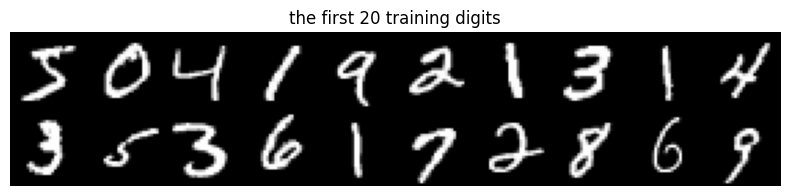

In [2]:
train_set = datasets.MNIST('data', train=True, download=True)
test_set = datasets.MNIST('data', train=False)

# The whole dataset fits in memory: pixel values from 0 (black) to 1 (white)
X = (train_set.data.float() / 255).to(device)          # (60000, 28, 28)
y = train_set.targets.to(device)
X_test = (test_set.data.float() / 255).to(device)      # (10000, 28, 28)
y_test = test_set.targets.to(device)
print(X.shape, X_test.shape)

def tile(images, cols):
    """Arrange a stack of images (n, H, W) into one picture with `cols` columns."""
    images = np.asarray(images.detach().cpu() if torch.is_tensor(images) else images)
    n, h, w = images.shape
    rows = int(np.ceil(n / cols))
    sheet = np.zeros((rows * h, cols * w), dtype=images.dtype)
    for k, image in enumerate(images):
        sheet[k // cols * h:(k // cols + 1) * h, k % cols * w:(k % cols + 1) * w] = image
    return sheet

def show(images, cols, title='', width=10):
    sheet = tile(images, cols)
    plt.figure(figsize=(width, width * sheet.shape[0] / sheet.shape[1]))
    plt.imshow(sheet, cmap='gray', vmin=0, vmax=1)
    plt.title(title); plt.axis('off'); plt.show()

def batches(n, size=128):
    """The indices of one epoch, in random order, `size` at a time."""
    order = torch.randperm(n, device=device)
    for start in range(0, n - size + 1, size):
        yield order[start:start + size]

show(X[:20], 10, 'the first 20 training digits')

## 1. Most Images Are Noise

A 28 x 28 grayscale image is a list of 784 numbers, each one of 256 values. Every possible list is an image, so there are $256^{784}$ of them: a number with about 1,900 digits. What does a typical one look like? Draw every pixel at random and see.

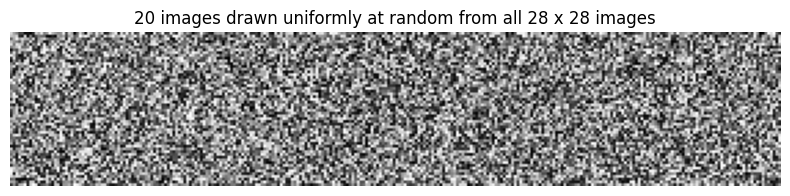

possible 28 x 28 images: a number with 1,889 digits
RESULT image_count_digits: 1889


In [3]:
rng = np.random.default_rng(0)
random_images = rng.integers(0, 256, size=(20, 28, 28)) / 255
show(random_images, 10, '20 images drawn uniformly at random from all 28 x 28 images')

digits_in_count = int(784 * np.log10(256)) + 1
print(f'possible 28 x 28 images: a number with {digits_in_count:,} digits')
print(f'RESULT image_count_digits: {digits_in_count}')

None of them is a digit, and you could draw for the lifetime of the universe without finding one. The images that mean something occupy a vanishingly thin part of the space of all images. The lecture calls that part the **manifold** of natural images (here: of handwritten digits).

So a generator cannot simply pick pixels. It has to learn where the digits are in the space of images. Every method in this notebook is a different way to learn that.

## 2. An Autoencoder, and the PCA of Lecture 11

Lecture 11 compressed an image to $k$ numbers by projecting it onto the top $k$ principal components, and got an approximation back by a weighted sum of those components. Both directions are **linear**.

An **autoencoder** does the same job with two small networks:

- the **encoder** turns the 784 pixels into $k$ numbers (the **code**, or **latent vector**);
- the **decoder** turns the $k$ numbers back into 784 pixels.

They are trained together, with the image itself as the target: the loss is the mean squared difference between the output and the input (the L2 loss of Lecture 13). No labels are needed. Because the code has only $k$ numbers, the network is forced to keep what matters about the digit and drop the rest.

The networks are the fully connected kind of Lecture 13.

In [4]:
class Autoencoder(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, k))
        self.decoder = nn.Sequential(nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())      # sigmoid: pixels between 0 and 1

    def decode(self, code):
        return self.decoder(code).view(-1, 28, 28)

    def forward(self, images):
        return self.decode(self.encoder(images))

def train_autoencoder(k, epochs=10, noise=0.0, seed=0):
    torch.manual_seed(seed)
    model = Autoencoder(k).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        for idx in batches(len(X)):
            clean = X[idx]
            given = clean + noise * torch.randn_like(clean)      # noise = 0: the input is the image itself
            loss = F.mse_loss(model(given), clean)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
    return model.eval()

small = stored('gv_small_networks.pth')
autoencoders = {}
start = time.time()
for k in (2, 8, 16, 32):
    if small is None:
        autoencoders[k] = train_autoencoder(k)
    else:
        autoencoders[k] = Autoencoder(k).to(device).eval()
        autoencoders[k].load_state_dict(small[f'autoencoder{k}'])
print('trained' if small is None else 'loaded', f'4 autoencoders in {time.time() - start:.0f} s')

loaded 4 autoencoders in 0 s


### The same number of stored values, two methods

PCA with $k$ components and an autoencoder with a $k$-number code both store $k$ numbers per image. Which one gives the better image back? Both are fitted on the training digits and scored on the 10,000 test digits, by the mean squared error per pixel.

k =  2   PCA error 0.0557   autoencoder error 0.0398
k =  8   PCA error 0.0375   autoencoder error 0.0195
k = 16   PCA error 0.0269   autoencoder error 0.0119
k = 32   PCA error 0.0169   autoencoder error 0.0101
RESULT pca_error: 0.0557 0.0375 0.0269 0.0169
RESULT ae_error: 0.0398 0.0195 0.0119 0.0101


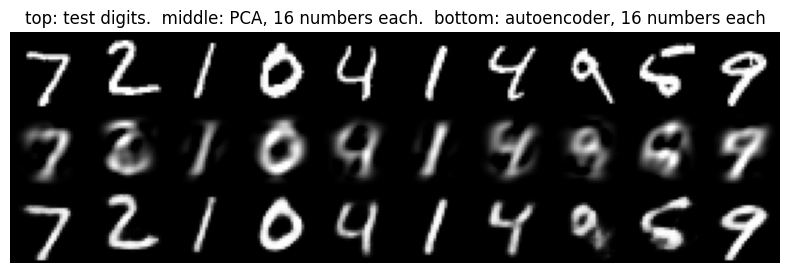

In [5]:
train_flat = X.flatten(1).cpu().numpy()
test_flat = X_test.flatten(1).cpu().numpy()
mean = train_flat.mean(axis=0)
# Principal components from 20,000 training digits (Lecture 11: the right singular vectors of the centered data)
_, _, Vt = np.linalg.svd(train_flat[:20000] - mean, full_matrices=False)

def pca_reconstruct(flat, k):
    components = Vt[:k]                                   # (k, 784)
    return (flat - mean) @ components.T @ components + mean

pca_error, ae_error = {}, {}
for k in (2, 8, 16, 32):
    pca_error[k] = float(((pca_reconstruct(test_flat, k) - test_flat) ** 2).mean())
    with torch.no_grad():
        ae_error[k] = F.mse_loss(autoencoders[k](X_test), X_test).item()
    print(f'k = {k:2d}   PCA error {pca_error[k]:.4f}   autoencoder error {ae_error[k]:.4f}')
print('RESULT pca_error:', ' '.join(f'{pca_error[k]:.4f}' for k in (2, 8, 16, 32)))
print('RESULT ae_error:', ' '.join(f'{ae_error[k]:.4f}' for k in (2, 8, 16, 32)))

with torch.no_grad():
    recon_rows = torch.cat([X_test[:10].cpu(),
                      torch.tensor(pca_reconstruct(test_flat[:10], 16)).view(10, 28, 28).clamp(0, 1).float(),
                      autoencoders[16](X_test[:10]).cpu()])
show(recon_rows, 10, 'top: test digits.  middle: PCA, 16 numbers each.  bottom: autoencoder, 16 numbers each')

The autoencoder wins at every size. PCA can only add up fixed patterns with weights, so its outputs look like blurred overlays. The decoder is nonlinear, so it can bend: the lecture's picture is that PCA fits a flat sheet to the data and an autoencoder fits a curved one.

### Does the network always win? The faces of Lecture 11

The same comparison on the 1,000 face windows of Lecture 11 (31 x 25 pixels), with 800 faces to fit on and 200 held out.

In [6]:
faces = np.load('data/faces1000.npy').astype(np.float32)
faces = (faces / faces.max()).reshape(1000, -1)                      # 775 pixels per face
order = np.random.default_rng(0).permutation(1000)
face_train, face_test = faces[order[:800]], faces[order[800:]]
face_mean = face_train.mean(axis=0)
_, _, face_Vt = np.linalg.svd(face_train - face_mean, full_matrices=False)

face_pca, face_ae = {}, {}
A, B = torch.tensor(face_train), torch.tensor(face_test)             # small enough for the CPU
for k in (2, 8, 16, 32):
    components = face_Vt[:k]
    face_pca[k] = float((((face_test - face_mean) @ components.T @ components + face_mean - face_test) ** 2).mean())
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(775, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, k),
                        nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 775), nn.Sigmoid())
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    for epoch in range(300):
        perm = torch.randperm(800)
        for start in range(0, 800, 64):
            batch = A[perm[start:start + 64]]
            loss = F.mse_loss(net(batch), batch)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
    with torch.no_grad():
        face_ae[k] = F.mse_loss(net(B), B).item()
    print(f'k = {k:2d}   PCA error {face_pca[k]:.4f}   autoencoder error {face_ae[k]:.4f}')
print('RESULT face_pca_error:', ' '.join(f'{face_pca[k]:.4f}' for k in (2, 8, 16, 32)))
print('RESULT face_ae_error:', ' '.join(f'{face_ae[k]:.4f}' for k in (2, 8, 16, 32)))

k =  2   PCA error 0.0070   autoencoder error 0.0064


k =  8   PCA error 0.0036   autoencoder error 0.0033


k = 16   PCA error 0.0024   autoencoder error 0.0027


k = 32   PCA error 0.0014   autoencoder error 0.0027
RESULT face_pca_error: 0.0070 0.0036 0.0024 0.0014
RESULT face_ae_error: 0.0064 0.0033 0.0027 0.0027


With 800 training faces the autoencoder is only ahead for the smallest codes, and PCA wins from 16 numbers up. A network has many more parameters to fit than PCA has, and 800 images are not enough to fit them well: the lesson of Lecture 15 again. With 60,000 digits, the network wins everywhere.

### A map of the digits

With $k = 2$ the code is a point in the plane, so we can look at it. Left: where the encoder puts 5,000 test digits. Right: what the decoder draws for a grid of points in the same plane.

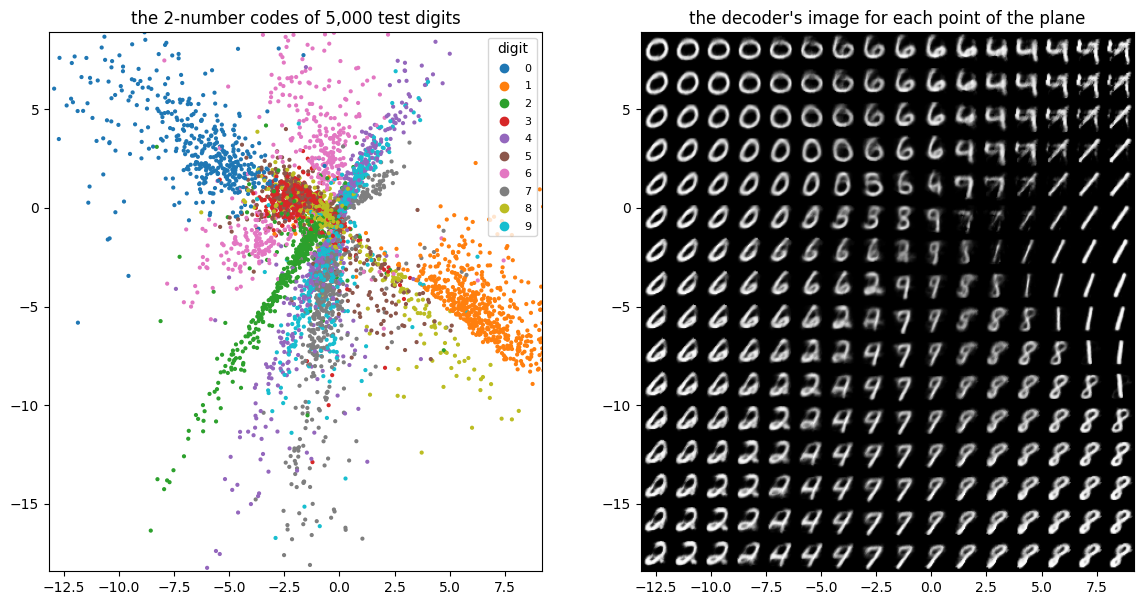

In [7]:
with torch.no_grad():
    codes2 = autoencoders[2].encoder(X_test).cpu().numpy()
labels_test = y_test.cpu().numpy()
low, high = np.percentile(codes2, 1, axis=0), np.percentile(codes2, 99, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
points = axes[0].scatter(codes2[:5000, 0], codes2[:5000, 1], c=labels_test[:5000], cmap='tab10', s=4)
axes[0].legend(*points.legend_elements(), title='digit', loc='upper right', fontsize=8)
axes[0].set_xlim(low[0], high[0]); axes[0].set_ylim(low[1], high[1])
axes[0].set_title('the 2-number codes of 5,000 test digits')

steps = 16
grid = np.array([[a, b] for b in np.linspace(high[1], low[1], steps) for a in np.linspace(low[0], high[0], steps)], dtype=np.float32)
with torch.no_grad():
    decoded_grid = autoencoders[2].decode(torch.tensor(grid, device=device)).cpu()
axes[1].imshow(tile(decoded_grid, steps), cmap='gray', extent=(low[0], high[0], low[1], high[1]), aspect='auto')
axes[1].set_title('the decoder\'s image for each point of the plane')
plt.show()

Nobody told the network which digit is which, yet the same digits land near each other, because similar images need similar codes to be rebuilt. Moving across the plane changes one digit smoothly into another. This is the "manifold" made visible, in two dimensions.

## 3. A Denoising Autoencoder

Change one thing in the training loop: give the network a **noisy** digit, and ask for the **clean** one. The network cannot copy its input any more. It has to know what digits look like, and push the noisy image back to the nearest clean digit.

Remember this idea. Section 7 builds a whole image generator out of it.

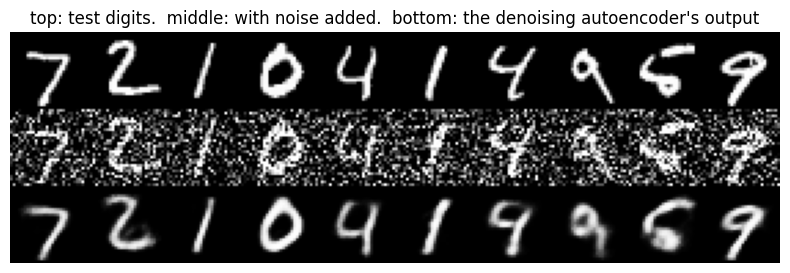

error of the noisy digits 0.1157, after denoising 0.0171
RESULT denoise_error: 0.1157 0.0171


In [8]:
NOISE = 0.5        # standard deviation of the added noise (pixel values run from 0 to 1)
if small is None:
    denoiser = train_autoencoder(32, noise=NOISE, seed=1)
else:
    denoiser = Autoencoder(32).to(device).eval()
    denoiser.load_state_dict(small['denoiser'])

torch.manual_seed(0)
noisy = X_test + NOISE * torch.randn_like(X_test)
with torch.no_grad():
    cleaned = denoiser(noisy)
noisy_error = F.mse_loss(noisy.clamp(0, 1), X_test).item()
cleaned_error = F.mse_loss(cleaned, X_test).item()
show(torch.cat([X_test[:10], noisy[:10].clamp(0, 1), cleaned[:10]]), 10,
     'top: test digits.  middle: with noise added.  bottom: the denoising autoencoder\'s output')
print(f'error of the noisy digits {noisy_error:.4f}, after denoising {cleaned_error:.4f}')
print(f'RESULT denoise_error: {noisy_error:.4f} {cleaned_error:.4f}')

Compare this with the Gaussian and median filters of Lecture 04. Those filters know nothing about the content: they average neighbors, and blur strokes along with the noise. This network removes noise by knowing what a digit is. The price is that it only works on digits.

## 4. Why an Autoencoder Is Not Yet a Generator

The decoder turns 16 numbers into an image. Could we generate new digits by feeding it 16 numbers of our own?

### First, a judge

To say how good a generated digit is, we need a measurement. We use two.

- **Confidence of a classifier.** A small CNN (the kind of Lecture 14) is trained to recognize the ten digits. On a clear digit, its largest softmax output is close to 1. On a shape that is not a digit, it is lower.
- **Gray share.** A pen stroke is white with a thin soft edge. A blurry image has wide gray zones. We measure the share of the non-black pixels (above 0.1) that are gray (below 0.6).

In [9]:
def make_classifier():
    return nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(64 * 7 * 7, 10)).to(device)

classifier = make_classifier()
if small is None:
    torch.manual_seed(0)
    optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
    for epoch in range(2):
        for idx in batches(len(X)):
            loss = F.cross_entropy(classifier(X[idx][:, None]), y[idx])
            optimizer.zero_grad(); loss.backward(); optimizer.step()
else:
    classifier.load_state_dict(small['classifier'])
classifier.eval()

def judge(images):
    """Mean confidence of the classifier on a stack of images in [0, 1], and its answer for each one."""
    with torch.no_grad():
        probabilities = classifier(images.to(device)[:, None]).softmax(dim=1)
    return probabilities.max(dim=1).values.mean().item(), probabilities.argmax(dim=1)

def gray_share(images):
    ink = images > 0.1
    return ((images < 0.6) & ink).sum().item() / ink.sum().item()

real_confidence, answers = judge(X_test)
accuracy = (answers == y_test).float().mean().item()
real_gray = gray_share(X_test)
print(f'classifier accuracy on the test digits: {accuracy:.3f}')
print(f'real test digits: confidence {real_confidence:.3f}, gray share {real_gray:.2f}')
print(f'RESULT classifier_accuracy: {accuracy:.4f}')
print(f'RESULT real_confidence: {real_confidence:.4f}')
print(f'RESULT real_gray: {real_gray:.4f}')

classifier accuracy on the test digits: 0.982
real test digits: confidence 0.980, gray share 0.30
RESULT classifier_accuracy: 0.9822
RESULT real_confidence: 0.9801
RESULT real_gray: 0.2971


### Halfway between two digits

Take two test digits and mix them, in two ways: average their **pixels**, or average their **codes** and decode the result.

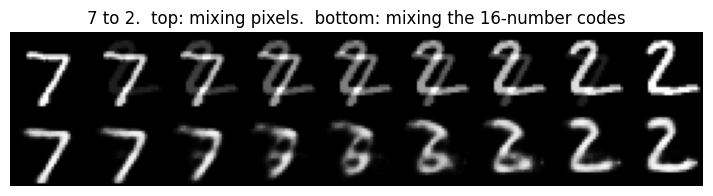

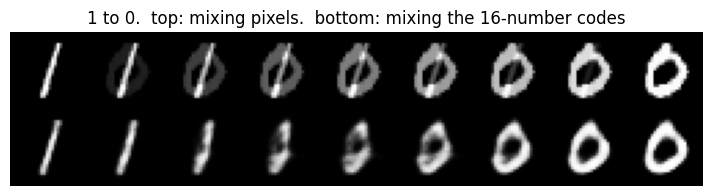

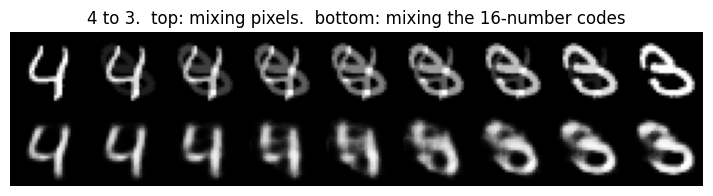

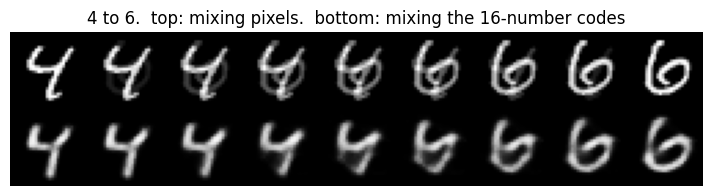

In [10]:
def interpolate(a, b, model, steps=9):
    weights = torch.linspace(0, 1, steps, device=device)[:, None]
    pixels = (1 - weights[:, :, None]) * X_test[a] + weights[:, :, None] * X_test[b]
    with torch.no_grad():
        code_a, code_b = model.encoder(X_test[a][None]), model.encoder(X_test[b][None])
        latent = model.decode((1 - weights) * code_a + weights * code_b)
    return pixels, latent

pairs = [(0, 1), (2, 3), (4, 18), (6, 11)]          # four pairs of test digits
strips = [torch.cat(interpolate(a, b, autoencoders[16])) for a, b in pairs]
for (a, b), strip in zip(pairs, strips):
    show(strip, 9, f'{y_test[a].item()} to {y_test[b].item()}.  top: mixing pixels.  bottom: mixing the 16-number codes', width=9)

Mixing pixels gives a double exposure: two digits on top of each other, which is not a digit. Mixing codes moves one shape toward the other, although the middle of the path is not always a clean digit.

### Random codes

Now the real test. Draw 16 random numbers, with the same mean and spread that the codes of real digits have, and decode them.

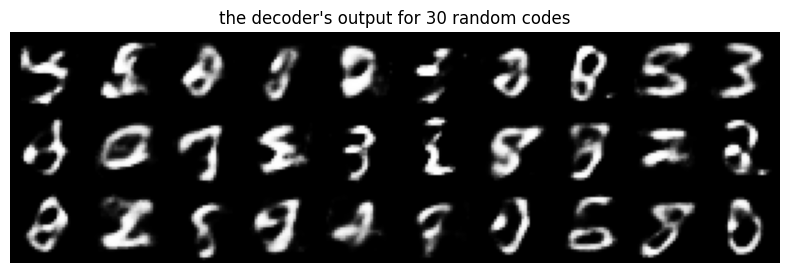

decoded random codes: confidence 0.746 (real digits 0.980), gray share 0.46 (real digits 0.30)
RESULT ae_random_confidence: 0.7460
RESULT ae_random_gray: 0.4641


In [11]:
with torch.no_grad():
    codes16 = autoencoders[16].encoder(X)
torch.manual_seed(0)
random_codes = codes16.mean(dim=0) + codes16.std(dim=0) * torch.randn(5000, 16, device=device)
with torch.no_grad():
    from_random_codes = autoencoders[16].decode(random_codes)
ae_confidence, _ = judge(from_random_codes)
ae_gray = gray_share(from_random_codes)
show(from_random_codes[:30], 10, 'the decoder\'s output for 30 random codes')
print(f'decoded random codes: confidence {ae_confidence:.3f} (real digits {real_confidence:.3f}), gray share {ae_gray:.2f} (real digits {real_gray:.2f})')
print(f'RESULT ae_random_confidence: {ae_confidence:.4f}')
print(f'RESULT ae_random_gray: {ae_gray:.4f}')

Some outputs are digits, and many are smudges and in-between shapes. The reason is in the map of Section 2: the codes of real digits fill only part of the latent space, and nothing in the training ever asked the decoder to do something sensible in the gaps between them. A random code often lands in a gap.

An autoencoder learns to **compress** digits. To **generate**, we need a decoder that turns *every* random code into a convincing digit. That needs a different way to train it.

## 5. Why the L2 Loss Produces Blur

The obvious way to train a network that outputs images is the L2 loss: make the output close to the right answer, pixel by pixel. The lecture's colorization example shows what goes wrong, and here is the same effect on digits.

**The task:** the network sees the **top half** of a digit and must draw the **bottom half**. Often the top half does not say which digit it is (the top of a 4 and the top of a 9 look alike), so several bottoms are correct.

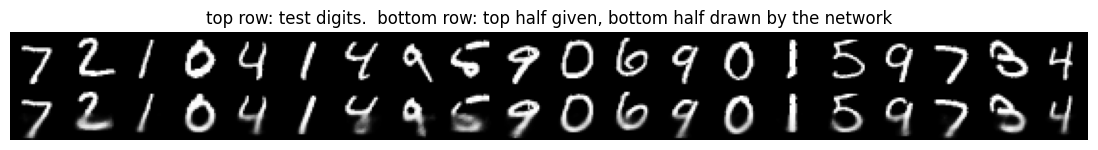

gray share of the true bottom halves 0.29, of the predicted ones 0.56
RESULT completion_gray: 0.2898 0.5620


In [12]:
def make_completer():
    return nn.Sequential(nn.Flatten(), nn.Linear(392, 512), nn.ReLU(), nn.Linear(512, 512), nn.ReLU(),
                         nn.Linear(512, 392), nn.Sigmoid()).to(device)

completer = make_completer()
if small is None:
    torch.manual_seed(0)
    optimizer = torch.optim.Adam(completer.parameters(), lr=1e-3)
    for epoch in range(10):
        for idx in batches(len(X)):
            top, bottom = X[idx][:, :14], X[idx][:, 14:]
            loss = F.mse_loss(completer(top), bottom.flatten(1))          # the L2 loss
            optimizer.zero_grad(); loss.backward(); optimizer.step()
else:
    completer.load_state_dict(small['completer'])
completer.eval()

with torch.no_grad():
    predicted_bottom = completer(X_test[:, :14]).view(-1, 14, 28)
completed = torch.cat([X_test[:, :14], predicted_bottom], dim=1)
show(torch.cat([X_test[:20], completed[:20]]), 20, 'top row: test digits.  bottom row: top half given, bottom half drawn by the network', width=14)

bottom_gray_true, bottom_gray_predicted = gray_share(X_test[:, 14:]), gray_share(predicted_bottom)
print(f'gray share of the true bottom halves {bottom_gray_true:.2f}, of the predicted ones {bottom_gray_predicted:.2f}')
print(f'RESULT completion_gray: {bottom_gray_true:.4f} {bottom_gray_predicted:.4f}')

Where the top half settles the answer, the bottom is drawn well. Where it does not, the network draws a gray smear. Why? Look at what the training data says about one such top half. Below, we find the 8 training digits whose top halves are most similar to a test digit's top half (the nearest neighbors of Lecture 12), and look at their bottoms.

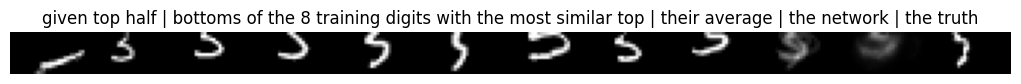

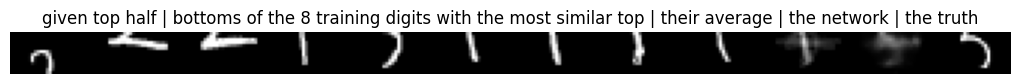

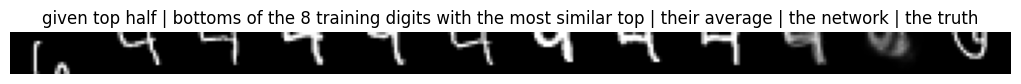

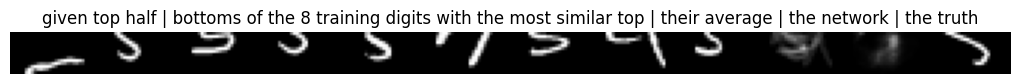

In [13]:
def explain(test_index, neighbors=8):
    top = X_test[test_index, :14]
    distance = ((X[:, :14] - top) ** 2).flatten(1).sum(dim=1)
    nearest = distance.argsort()[:neighbors]
    bottoms = X[nearest, 14:]
    row = torch.cat([bottoms, bottoms.mean(dim=0, keepdim=True), predicted_bottom[test_index][None], X_test[test_index, 14:][None]])
    return row

# the test digits whose predicted bottom is most gray: the most uncertain cases
ink = (predicted_bottom > 0.1).flatten(1)
gray = ((predicted_bottom < 0.6).flatten(1) & ink).sum(dim=1) / ink.sum(dim=1).clamp(min=1)
uncertain = [i for i in gray.argsort(descending=True).tolist() if ink[i].sum() > 60][:4]
explain_rows = [explain(i) for i in uncertain]
for i, row in zip(uncertain, explain_rows):
    show(torch.cat([X_test[i, :14][None], row]), 12,
         'given top half | bottoms of the 8 training digits with the most similar top | their average | the network | the truth', width=13)

The training digits with nearly the same top half continue in different ways. A network trained with the L2 loss cannot pick one of them. The output that minimizes the squared error against all of them is their **average**, and the average of several sharp strokes in different places is a gray blur. (Lecture 13: the number that minimizes the squared distance to a set of numbers is their mean.)

This is the lecture's "regression to the mean". Every pixel-wise loss has this problem whenever more than one answer is correct, and for generating images, many answers are always correct. We need a loss that says "this looks like a real digit" instead of "this is close to that particular digit".

## 6. A Small GAN

A **generative adversarial network** learns that loss. It trains two networks against each other:

- the **generator** $G$ turns 64 random numbers (the latent vector $z$) into an image. It is a decoder, built from the transposed convolutions of Lecture 16;
- the **discriminator** $D$ is a CNN classifier with two classes, "real" and "generated" (Lecture 14), with a single output: its score that the image is real.

Each training step has two parts, and both use the cross-entropy loss of Lecture 13.

1. **Train $D$:** show it a batch of real digits (target 1) and a batch from $G$ (target 0).
2. **Train $G$:** generate a batch, and change $G$'s weights so that $D$ calls the batch real (target 1). The gradient flows through $D$ back into $G$, but only $G$'s weights are updated.

For $G$, the discriminator *is* the loss function: one that was learned, not written by hand. It never compares an output with one particular digit, so it never rewards an average.

In [14]:
LATENT = 64

def make_generator():
    return nn.Sequential(
        nn.Linear(LATENT, 128 * 7 * 7), nn.Unflatten(1, (128, 7, 7)), nn.BatchNorm2d(128), nn.ReLU(),     # 7 x 7
        nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),                # 14 x 14
        nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1), nn.Tanh()).to(device)                           # 28 x 28, values in [-1, 1]

def make_discriminator():
    return nn.Sequential(
        nn.Conv2d(1, 64, 4, stride=2, padding=1), nn.LeakyReLU(0.2),                                       # 14 x 14
        nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),                # 7 x 7
        nn.Flatten(), nn.Linear(128 * 7 * 7, 1)).to(device)                                                # one score (a logit)

def to_image(output):
    """Generator outputs are in [-1, 1]; images are in [0, 1]."""
    return ((output[:, 0] + 1) / 2).clamp(0, 1)

GAN_EPOCHS = 10
generator, discriminator = make_generator(), make_discriminator()
fixed_z = torch.randn(64, LATENT, generator=torch.Generator().manual_seed(0)).to(device)    # the same 64 latent vectors after every epoch
gan = stored('gv_gan.pth')
if gan is None:
    torch.manual_seed(0)
    optimizer_G = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    real_images = X[:, None] * 2 - 1                         # scaled to [-1, 1], like the generator's output
    history = {'loss_D': [], 'loss_G': [], 'score_real': [], 'score_fake': [], 'samples': [], 'counts': []}
    start = time.time()
    for epoch in range(GAN_EPOCHS):
        sums = np.zeros(4); n = 0
        for idx in batches(len(X)):
            real = real_images[idx]
            fake = generator(torch.randn(len(idx), LATENT, device=device))

            # 1. the discriminator: real -> 1, generated -> 0
            score_real, score_fake = discriminator(real), discriminator(fake.detach())      # detach: do not touch G here
            loss_D = (F.binary_cross_entropy_with_logits(score_real, torch.ones_like(score_real)) +
                      F.binary_cross_entropy_with_logits(score_fake, torch.zeros_like(score_fake)))
            optimizer_D.zero_grad(); loss_D.backward(); optimizer_D.step()

            # 2. the generator: make the discriminator say "real"
            score = discriminator(fake)
            loss_G = F.binary_cross_entropy_with_logits(score, torch.ones_like(score))
            optimizer_G.zero_grad(); loss_G.backward(); optimizer_G.step()

            sums += [loss_D.item(), loss_G.item(), torch.sigmoid(score_real).mean().item(), torch.sigmoid(score_fake).mean().item()]
            n += 1
        generator.eval()
        with torch.no_grad():
            history['samples'].append(to_image(generator(fixed_z)).cpu())
            made = to_image(generator(torch.randn(5000, LATENT, device=device)))
        history['counts'].append(torch.bincount(judge(made)[1], minlength=10).cpu())
        generator.train()
        for key, value in zip(('loss_D', 'loss_G', 'score_real', 'score_fake'), sums / n):
            history[key].append(float(value))
        print(f'epoch {epoch + 1:2d}  loss D {sums[0] / n:.2f}  loss G {sums[1] / n:.2f}  D(real) {sums[2] / n:.2f}  D(generated) {sums[3] / n:.2f}  {time.time() - start:.0f} s')
    gan = {'generator': generator.state_dict(), 'discriminator': discriminator.state_dict(), 'history': history}
    torch.save(gan, 'output/gv_gan.pth')
else:
    generator.load_state_dict(gan['generator']); discriminator.load_state_dict(gan['discriminator'])
    history = gan['history']
    for epoch in range(GAN_EPOCHS):
        print(f"epoch {epoch + 1:2d}  loss D {history['loss_D'][epoch]:.2f}  loss G {history['loss_G'][epoch]:.2f}  D(real) {history['score_real'][epoch]:.2f}  D(generated) {history['score_fake'][epoch]:.2f}  (stored)")
generator.eval(); discriminator.eval()
print('RESULT gan_score_real:', ' '.join(f'{v:.3f}' for v in history['score_real']))
print('RESULT gan_score_fake:', ' '.join(f'{v:.3f}' for v in history['score_fake']))

epoch  1  loss D 0.52  loss G 1.92  D(real) 0.79  D(generated) 0.21  (stored)
epoch  2  loss D 0.30  loss G 2.55  D(real) 0.88  D(generated) 0.12  (stored)
epoch  3  loss D 0.26  loss G 2.84  D(real) 0.90  D(generated) 0.10  (stored)
epoch  4  loss D 0.31  loss G 2.75  D(real) 0.88  D(generated) 0.12  (stored)
epoch  5  loss D 0.37  loss G 2.60  D(real) 0.86  D(generated) 0.14  (stored)
epoch  6  loss D 0.37  loss G 2.57  D(real) 0.86  D(generated) 0.14  (stored)
epoch  7  loss D 0.37  loss G 2.59  D(real) 0.86  D(generated) 0.14  (stored)
epoch  8  loss D 0.41  loss G 2.53  D(real) 0.85  D(generated) 0.15  (stored)
epoch  9  loss D 0.37  loss G 2.60  D(real) 0.86  D(generated) 0.14  (stored)
epoch 10  loss D 0.38  loss G 2.62  D(real) 0.86  D(generated) 0.14  (stored)
RESULT gan_score_real: 0.789 0.877 0.896 0.879 0.861 0.858 0.858 0.847 0.857 0.856
RESULT gan_score_fake: 0.214 0.124 0.104 0.121 0.140 0.142 0.142 0.153 0.144 0.144


Two things are different from every training run so far in this course.

- **The losses do not go to zero.** In Lectures 13 to 17 a falling loss meant progress. Here the two losses pull against each other, and a balance is the healthy state: if $D$ won completely, $G$ would get no useful gradient, and the reverse.
- **There is no accuracy to report.** $D$(real) and $D$(generated) are the discriminator's average scores for the two kinds of image. To see whether the generator improves, we have to look at its images.

Below: the images for the same 64 latent vectors after epochs 1, 2, 5 and 10.

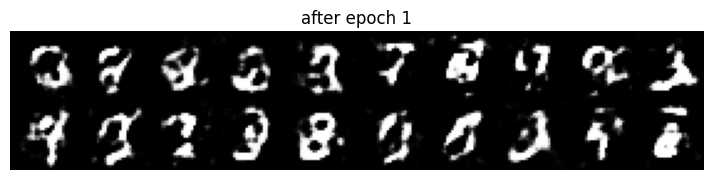

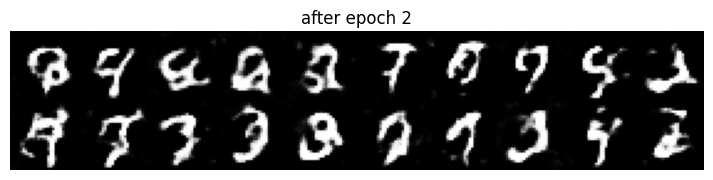

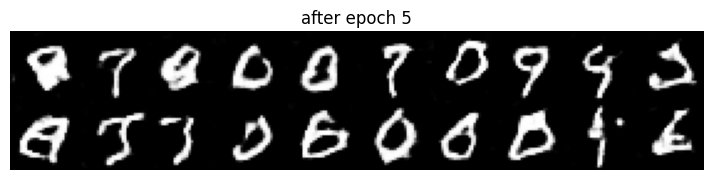

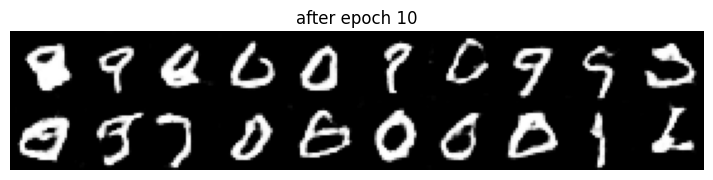

In [15]:
for epoch in (1, 2, 5, 10):
    show(history['samples'][epoch - 1][:20], 10, f'after epoch {epoch}', width=9)

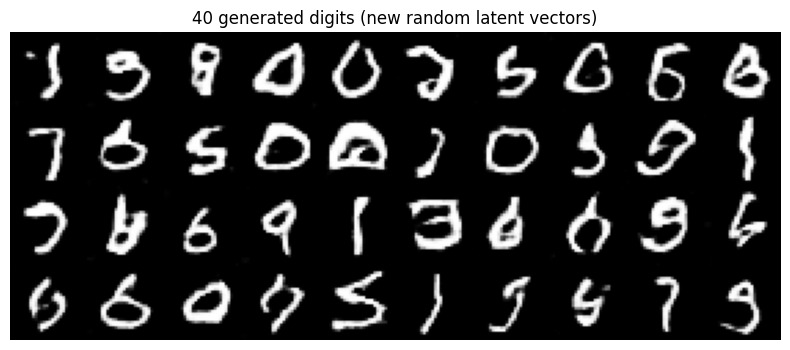

generated digits: confidence 0.850 (real 0.980), gray share 0.25 (real 0.30)


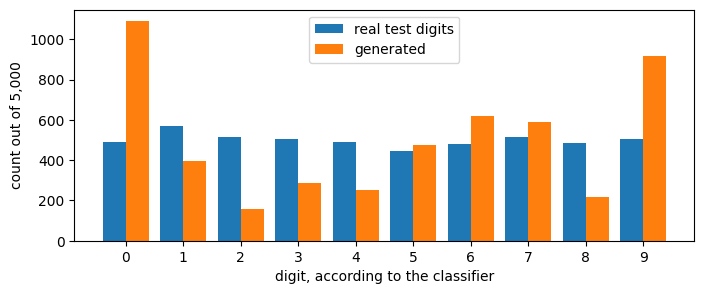

RESULT gan_confidence: 0.8497
RESULT gan_gray: 0.2516
RESULT gan_counts: 1093 394 156 286 253 474 618 588 219 919
RESULT real_counts: 490 567 516 505 491 446 479 514 487 504


In [16]:
torch.manual_seed(1)
with torch.no_grad():
    gan_images = to_image(generator(torch.randn(5000, LATENT, device=device)))
gan_confidence, gan_answers = judge(gan_images)
gan_gray = gray_share(gan_images)
gan_counts = torch.bincount(gan_answers, minlength=10).cpu().numpy()
real_counts = torch.bincount(y_test, minlength=10).cpu().numpy() / 2          # per 5,000 test digits

show(gan_images[:40], 10, '40 generated digits (new random latent vectors)')
print(f'generated digits: confidence {gan_confidence:.3f} (real {real_confidence:.3f}), gray share {gan_gray:.2f} (real {real_gray:.2f})')
plt.figure(figsize=(8, 3))
plt.bar(np.arange(10) - 0.2, real_counts, 0.4, label='real test digits'); plt.bar(np.arange(10) + 0.2, gan_counts, 0.4, label='generated')
plt.xticks(range(10)); plt.xlabel('digit, according to the classifier'); plt.ylabel('count out of 5,000'); plt.legend(); plt.show()
print(f'RESULT gan_confidence: {gan_confidence:.4f}')
print(f'RESULT gan_gray: {gan_gray:.4f}')
print('RESULT gan_counts:', ' '.join(str(c) for c in gan_counts))
print('RESULT real_counts:', ' '.join(str(int(c)) for c in real_counts))

The strokes are sharp: the gray share is at the level of real digits, not of the blurry outputs of Sections 4 and 5. Not every output is a clean digit, and the classifier is less sure about them than about real ones.

The bar chart shows a known weakness. Nothing in the training asks the generator to make all ten digits equally often: it only has to fool $D$ one image at a time. So it makes some digits more often than the data does, and others less. In the extreme case a generator produces only a few kinds of output, which is called **mode collapse**.

### Walking through the latent space

Unlike the autoencoder's decoder, the generator was trained on random latent vectors, so every point is supposed to give a digit. Mix two latent vectors and watch the image.

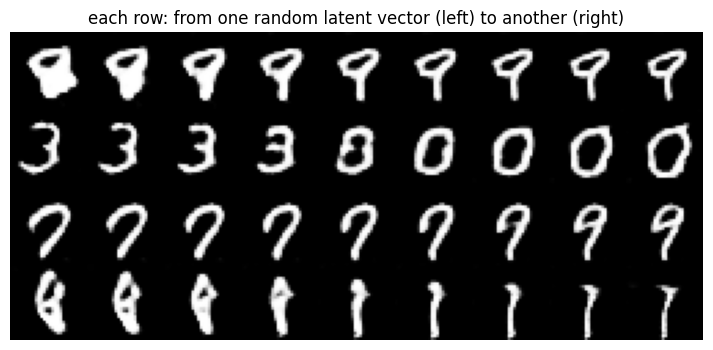

In [17]:
def gan_walk(seed, steps=9):
    z = torch.randn(2, LATENT, generator=torch.Generator().manual_seed(seed)).to(device)
    weights = torch.linspace(0, 1, steps, device=device)[:, None]
    with torch.no_grad():
        return to_image(generator((1 - weights) * z[0] + weights * z[1]))

gan_walks = [gan_walk(seed) for seed in range(6)]
show(torch.cat(gan_walks[:4]), 9, 'each row: from one random latent vector (left) to another (right)', width=9)

## 7. A Small Diffusion Model

A GAN makes an image in one step, from noise to digit, and that step is hard to learn. A **diffusion model** splits it into many small steps, each of which is easy: **remove a little noise**. It is the denoising network of Section 3, applied again and again.

### Destroying a digit, step by step

First the easy direction. Take a digit $x_0$ and mix it with Gaussian noise. With $T = 1000$ noise levels, the image at level $t$ is

$$x_t = \sqrt{\bar\alpha_t}\; x_0 + \sqrt{1 - \bar\alpha_t}\; \epsilon$$

where $\epsilon$ is an image of pure noise and $\bar\alpha_t$ is a number that falls from almost 1 (at $t = 0$: all digit) to almost 0 (at $t = 999$: all noise). The values of $\bar\alpha_t$ are fixed in advance by the designer; nothing here is learned. Pixel values are scaled to $[-1, 1]$, so that the digit and the noise have a similar range.

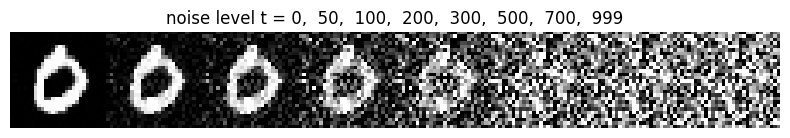

share of the digit left: t=0: 1.00, t=50: 0.98, t=100: 0.95, t=200: 0.81, t=300: 0.63, t=500: 0.28, t=700: 0.08, t=999: 0.01


In [18]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=device)        # how much noise each step adds (Ho et al., 2020)
alpha_bar = torch.cumprod(1 - betas, dim=0)                 # how much of the original digit is left at level t

def add_noise(x0, t, noise):
    """The image at noise level t (t: one level per image)."""
    keep = alpha_bar[t].sqrt()[:, None, None, None]
    return keep * x0 + (1 - alpha_bar[t]).sqrt()[:, None, None, None] * noise

levels = [0, 50, 100, 200, 300, 500, 700, 999]
digit = (X_test[3] * 2 - 1)[None, None].repeat(len(levels), 1, 1, 1)
forward_noise = torch.randn(1, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(device).repeat(len(levels), 1, 1, 1)
forward_example = add_noise(digit, torch.tensor(levels, device=device), forward_noise)
show(((forward_example[:, 0] + 1) / 2).clamp(0, 1), len(levels), 'noise level t = ' + ',  '.join(str(t) for t in levels))
print('share of the digit left:', ', '.join(f't={t}: {alpha_bar[t].sqrt().item():.2f}' for t in levels))

### The network: a U-Net that predicts the noise

Destroying is easy. To go back, we train a network for one job: given a noisy image $x_t$ and the level $t$, **predict the noise $\epsilon$ that was added**. If we know the noise, we can subtract it.

- It maps an image to an image of the same size, so it is a **U-Net** (Lecture 16): convolutions and pooling on the way down, transposed convolutions on the way up, and skip connections.
- It also needs to know **how noisy** its input is, and (optionally) **which digit** we want. Both are given as a short vector: $t$ written as a few sine and cosine waves, followed by a one-hot vector for the digit (all zeros means "any digit"). A small fully connected network turns this vector into one number per channel, which is added to the feature maps of every block.
- The loss is the **L2 loss** between the predicted and the true noise. Training needs no labels beyond that: we add the noise ourselves, so we know the answer.

In [19]:
class Block(nn.Module):
    """Two 3 x 3 convolutions; the condition vector shifts every channel of the first one."""
    def __init__(self, c_in, c_out):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv2d(c_in, c_out, 3, padding=1), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.norm1, self.norm2 = nn.GroupNorm(8, c_out), nn.GroupNorm(8, c_out)
        self.shift = nn.Linear(128, c_out)

    def forward(self, x, condition):
        x = F.relu(self.norm1(self.conv1(x))) + self.shift(condition)[:, :, None, None]
        return F.relu(self.norm2(self.conv2(x)))

class UNet(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.condition = nn.Sequential(nn.Linear(32 + 10, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU())
        self.down1, self.down2, self.middle = Block(1, width), Block(width, 2 * width), Block(2 * width, 4 * width)
        self.upsample2, self.up2 = nn.ConvTranspose2d(4 * width, 2 * width, 2, stride=2), Block(4 * width, 2 * width)
        self.upsample1, self.up1 = nn.ConvTranspose2d(2 * width, width, 2, stride=2), Block(2 * width, width)
        self.out = nn.Conv2d(width, 1, 1)

    def forward(self, x, t, onehot):
        waves = t[:, None].float() / T * (2.0 ** torch.arange(16, device=x.device)) * (np.pi / 2)     # t as 16 frequencies
        c = self.condition(torch.cat([waves.sin(), waves.cos(), onehot], dim=1))
        a = self.down1(x, c)                                            # 28 x 28
        b = self.down2(F.max_pool2d(a, 2), c)                           # 14 x 14
        m = self.middle(F.max_pool2d(b, 2), c)                          # 7 x 7
        b = self.up2(torch.cat([self.upsample2(m), b], dim=1), c)       # skip connection from the way down
        a = self.up1(torch.cat([self.upsample1(b), a], dim=1), c)
        return self.out(a)                                              # the predicted noise, 28 x 28

unet = UNet().to(device)
print(f'{sum(p.numel() for p in unet.parameters()):,} parameters')

530,529 parameters


In [20]:
DIFFUSION_EPOCHS = 15
diffusion = stored('gv_diffusion.pth')
if diffusion is None:
    torch.manual_seed(0)
    optimizer = torch.optim.Adam(unet.parameters(), lr=1e-3)
    real_images = X[:, None] * 2 - 1
    diffusion_loss = []
    start = time.time()
    for epoch in range(DIFFUSION_EPOCHS):
        total = 0; n = 0
        for idx in batches(len(X)):
            x0 = real_images[idx]
            t = torch.randint(0, T, (len(idx),), device=device)          # a random noise level for every image
            noise = torch.randn_like(x0)
            onehot = F.one_hot(y[idx], 10).float()
            onehot = onehot * (torch.rand(len(idx), 1, device=device) > 0.1)      # 1 time in 10: hide the label
            loss = F.mse_loss(unet(add_noise(x0, t, noise), t, onehot), noise)    # L2 between predicted and true noise
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item(); n += 1
        diffusion_loss.append(total / n)
        print(f'epoch {epoch + 1:2d}  loss {total / n:.4f}  {time.time() - start:.0f} s')
    diffusion = {'unet': unet.state_dict(), 'loss': diffusion_loss}
    torch.save(diffusion, 'output/gv_diffusion.pth')
else:
    unet.load_state_dict(diffusion['unet'])
    print('stored network; loss per epoch:', ' '.join(f'{v:.4f}' for v in diffusion['loss']))
unet.eval()
print('RESULT diffusion_loss:', ' '.join(f'{v:.4f}' for v in diffusion['loss']))

stored network; loss per epoch: 0.0696 0.0355 0.0311 0.0292 0.0277 0.0269 0.0265 0.0257 0.0253 0.0251 0.0246 0.0246 0.0244 0.0241 0.0239
RESULT diffusion_loss: 0.0696 0.0355 0.0311 0.0292 0.0277 0.0269 0.0265 0.0257 0.0253 0.0251 0.0246 0.0246 0.0244 0.0241 0.0239


This loss does go down steadily, and there is only one network: training a diffusion model is as calm as training a classifier. That is one reason diffusion models replaced GANs in most applications.

### Generating: from noise to a digit

Start from an image of pure noise, at level $t = 999$. Then repeat:

1. ask the network for the noise in the current image;
2. subtract it, which gives an **estimate of the clean digit**;
3. do not trust that estimate fully: mix it with noise again, down to the *next, slightly lower* noise level.

Each round the estimate gets better, because the network sees a less noisy input. We can visit all 1,000 levels, or skip most of them and take 100, 20 or 5 bigger steps.

noise levels shown: [999, 696, 494, 343, 242, 141, 71, 0]


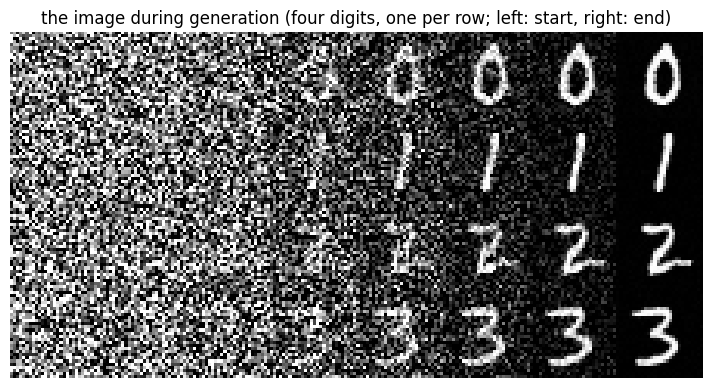

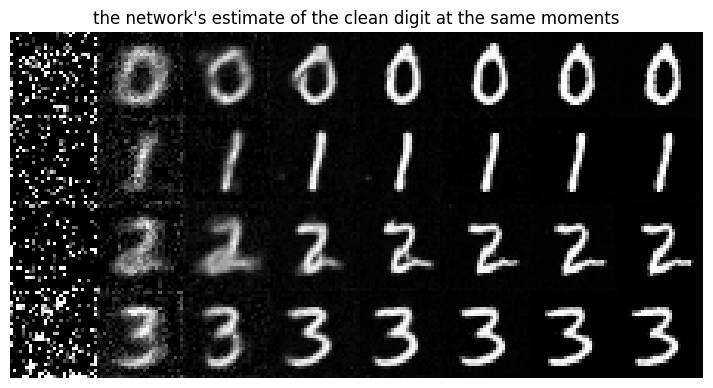

In [21]:
@torch.no_grad()
def generate(n, labels=None, steps=100, seed=0, record=False):
    """n digits from noise. labels: a tensor of digits, or None for 'any digit'. Returns images in [0, 1]."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 1, 28, 28, generator=g).to(device)                       # pure noise
    onehot = torch.zeros(n, 10, device=device) if labels is None else F.one_hot(labels.to(device), 10).float()
    levels = torch.linspace(T - 1, 0, steps).round().long().tolist()            # for example 999, 989, ..., 10, 0
    recorded = []
    for j, t in enumerate(levels):
        noise = unet(x, torch.full((n,), t, device=device), onehot)             # 1. the predicted noise
        x0 = ((x - (1 - alpha_bar[t]).sqrt() * noise) / alpha_bar[t].sqrt()).clamp(-1, 1)     # 2. the estimated clean digit
        if record:
            recorded.append((t, x[:, 0].cpu(), x0[:, 0].cpu()))
        if j + 1 == len(levels):
            x = x0
            break
        s = levels[j + 1]                                                       # 3. back to the lower noise level s
        noise = (x - alpha_bar[t].sqrt() * x0) / (1 - alpha_bar[t]).sqrt()
        fresh = ((1 - alpha_bar[s]) / (1 - alpha_bar[t]) * (1 - alpha_bar[t] / alpha_bar[s])).sqrt()   # how much new noise (Ho et al., 2020)
        x = alpha_bar[s].sqrt() * x0 + (1 - alpha_bar[s] - fresh ** 2).sqrt() * noise + fresh * torch.randn(x.shape, generator=g).to(device)
    images = ((x[:, 0] + 1) / 2).clamp(0, 1)
    return (images, recorded) if record else images

images, recorded = generate(8, labels=torch.arange(8), steps=100, seed=3, record=True)
chosen = [0, 30, 50, 65, 75, 85, 92, 99]
print('noise levels shown:', [recorded[j][0] for j in chosen])
show(torch.cat([((recorded[j][1][k] + 1) / 2).clamp(0, 1)[None] for k in range(4) for j in chosen]), len(chosen),
     'the image during generation (four digits, one per row; left: start, right: end)', width=9)
show(torch.cat([((recorded[j][2][k] + 1) / 2)[None] for k in range(4) for j in chosen]), len(chosen),
     'the network\'s estimate of the clean digit at the same moments', width=9)

The top picture is the image itself, which stays noisy almost to the end. The bottom one is the network's current guess of the final digit. At the very first step it is still noise. Soon after, it is a soft blob (from a very noisy image, the best guess is an average of many digits, the blur of Section 5), then a rough shape, then details. A diffusion model decides the layout first and the fine strokes last.

### Asking for a digit, and getting many different ones

The one-hot vector tells the network which digit to draw: this is **class conditioning**. Different starting noise gives a different handwriting of the same digit.

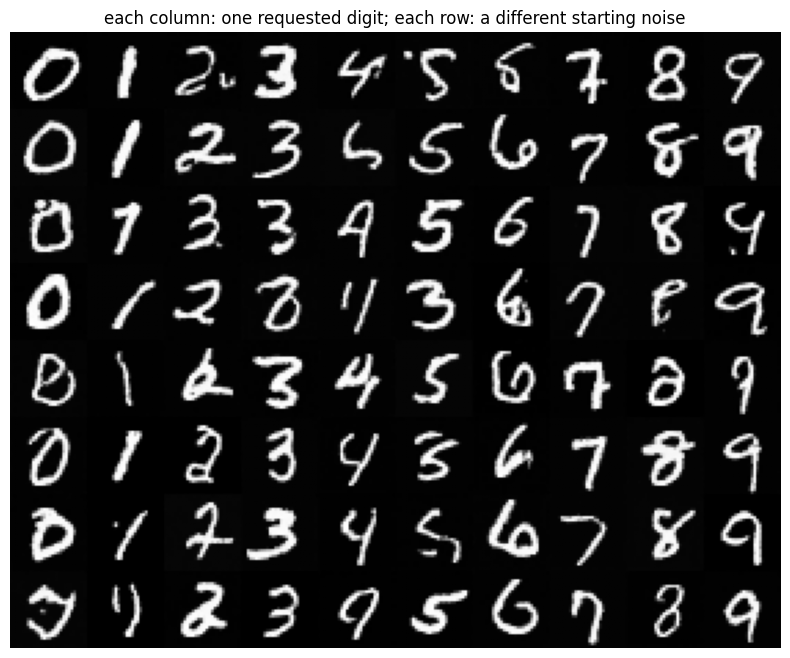

1,000 generated digits: the classifier agrees with the requested digit for 86.6%
confidence 0.940 (real 0.980), gray share 0.32 (real 0.30)
RESULT diffusion_match: 0.8660
RESULT diffusion_confidence: 0.9402
RESULT diffusion_gray: 0.3212


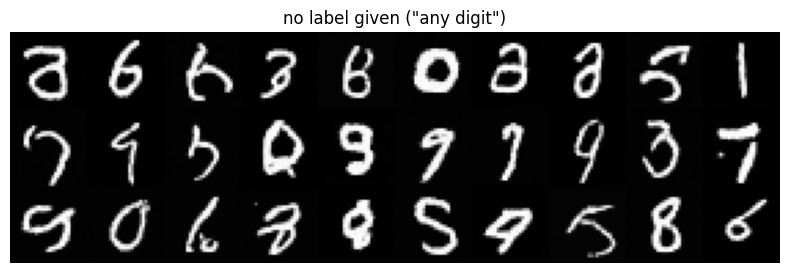

digits made without a label, per 1,000: [137, 49, 108, 81, 88, 97, 80, 111, 90, 159]
RESULT diffusion_unconditional_counts: 137 49 108 81 88 97 80 111 90 159


In [22]:
requested = torch.arange(10).repeat(8)                    # 0..9, eight times
start = time.time()
conditional = generate(80, labels=requested, steps=100, seed=0)
seconds_100 = time.time() - start
show(conditional, 10, 'each column: one requested digit; each row: a different starting noise')

many = torch.arange(10).repeat(100)
diffusion_images = generate(1000, labels=many, steps=100, seed=1)
diffusion_confidence, diffusion_answers = judge(diffusion_images)
match = (diffusion_answers.cpu() == many).float().mean().item()
diffusion_gray = gray_share(diffusion_images)
print(f'1,000 generated digits: the classifier agrees with the requested digit for {match:.1%}')
print(f'confidence {diffusion_confidence:.3f} (real {real_confidence:.3f}), gray share {diffusion_gray:.2f} (real {real_gray:.2f})')
print(f'RESULT diffusion_match: {match:.4f}')
print(f'RESULT diffusion_confidence: {diffusion_confidence:.4f}')
print(f'RESULT diffusion_gray: {diffusion_gray:.4f}')

unconditional = generate(1000, labels=None, steps=100, seed=2)
unconditional_counts = torch.bincount(judge(unconditional)[1], minlength=10).cpu().numpy()
show(unconditional[:30], 10, 'no label given ("any digit")')
print('digits made without a label, per 1,000:', unconditional_counts.tolist())
print('RESULT diffusion_unconditional_counts:', ' '.join(str(c) for c in unconditional_counts))

A one-hot vector can only ask for one of a fixed list of classes. A text-to-image model replaces it with a vector computed from a sentence by another network (in the way ResNet-18 turned a photo into 512 numbers in Lecture 15). The rest of the method is what you see here.

### How many steps?

Every step is one pass through the U-Net, so 1,000 steps cost 1,000 passes. What happens with fewer?

 1000 steps:   20.7 s for 200 digits, gray share 0.33, classifier agrees 89%


  100 steps:    2.1 s for 200 digits, gray share 0.33, classifier agrees 92%


   20 steps:    0.4 s for 200 digits, gray share 0.35, classifier agrees 92%
    5 steps:    0.1 s for 200 digits, gray share 0.54, classifier agrees 90%


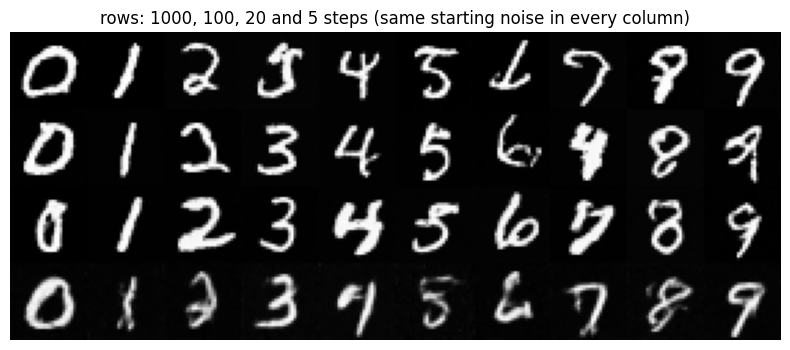

RESULT step_seconds: 20.65 2.09 0.41 0.11
RESULT step_gray: 0.3298 0.3267 0.3503 0.5427
RESULT step_match: 0.8950 0.9200 0.9200 0.9000


In [23]:
step_images, step_seconds, step_gray, step_match = {}, {}, {}, {}
labels_200 = torch.arange(10).repeat(20)
for steps in (1000, 100, 20, 5):
    if device.type == 'cuda': torch.cuda.synchronize()
    start = time.time()
    step_images[steps] = generate(200, labels=labels_200, steps=steps, seed=5)
    if device.type == 'cuda': torch.cuda.synchronize()
    step_seconds[steps] = time.time() - start
    step_gray[steps] = gray_share(step_images[steps])
    step_match[steps] = (judge(step_images[steps])[1].cpu() == labels_200).float().mean().item()
    print(f'{steps:5d} steps: {step_seconds[steps]:6.1f} s for 200 digits, gray share {step_gray[steps]:.2f}, classifier agrees {step_match[steps]:.0%}')
show(torch.cat([step_images[steps][:10] for steps in (1000, 100, 20, 5)]), 10, 'rows: 1000, 100, 20 and 5 steps (same starting noise in every column)')
print('RESULT step_seconds:', ' '.join(f'{step_seconds[s]:.2f}' for s in (1000, 100, 20, 5)))
print('RESULT step_gray:', ' '.join(f'{step_gray[s]:.4f}' for s in (1000, 100, 20, 5)))
print('RESULT step_match:', ' '.join(f'{step_match[s]:.4f}' for s in (1000, 100, 20, 5)))

With very few steps, the output is the blurry "average" estimate that the network makes from heavy noise: recognizable, but soft and gray, like the L2 outputs of Section 5. More steps give the strokes of real handwriting. Beyond a certain number, more steps cost time without a visible gain, which is why practical systems use tens of steps, not a thousand.

## 8. Side by Side

The three generators of this notebook, measured in the same way, and timed for a batch of 64 images.

In [24]:
def timed(function, repeats=3):
    best = float('inf')
    for _ in range(repeats):
        if device.type == 'cuda': torch.cuda.synchronize()
        start = time.time(); function()
        if device.type == 'cuda': torch.cuda.synchronize()
        best = min(best, time.time() - start)
    return best

z64 = torch.randn(64, LATENT, device=device)
with torch.no_grad():
    time_decoder = timed(lambda: autoencoders[16].decode(random_codes[:64]))
    time_gan = timed(lambda: generator(z64))
time_diffusion_100 = timed(lambda: generate(64, steps=100), repeats=1)
time_diffusion_1000 = timed(lambda: generate(64, steps=1000), repeats=1)

print(f'{"":34s}{"confidence":>11s}{"gray share":>12s}{"time for 64 images":>21s}')
rows = [('real test digits', real_confidence, real_gray, None),
        ('autoencoder, random codes', ae_confidence, ae_gray, time_decoder),
        ('GAN', gan_confidence, gan_gray, time_gan),
        ('diffusion, 100 steps', diffusion_confidence, diffusion_gray, time_diffusion_100),
        ('diffusion, 1000 steps', None, step_gray[1000], time_diffusion_1000)]
for name, confidence, gray, seconds in rows:
    print(f'{name:34s}{"" if confidence is None else format(confidence, ".3f"):>11s}{gray:12.2f}{"" if seconds is None else format(seconds * 1000, ",.1f") + " ms":>21s}')
print(f'RESULT time_ms: {time_decoder * 1000:.2f} {time_gan * 1000:.2f} {time_diffusion_100 * 1000:.1f} {time_diffusion_1000 * 1000:.1f}')
print(f'RESULT passes_ratio: {time_diffusion_1000 / time_gan:.0f}')

                                   confidence  gray share   time for 64 images
real test digits                        0.980        0.30                     
autoencoder, random codes               0.746        0.46               0.3 ms
GAN                                     0.850        0.25               0.8 ms
diffusion, 100 steps                    0.940        0.32             766.7 ms
diffusion, 1000 steps                                0.33           7,603.4 ms
RESULT time_ms: 0.29 0.84 766.7 7603.4
RESULT passes_ratio: 9088


- The **autoencoder**'s decoder is fast, but random codes give blurry, uncertain shapes: it was trained to compress, not to generate.
- The **GAN** is as fast (one pass through a small network) and draws sharp strokes, but its training is a balancing act, and it does not cover all digits evenly.
- The **diffusion model** trains calmly with a plain L2 loss and can be told which digit to draw, but it needs many passes through its network for one batch of images.

These networks have about half a million parameters and make 28 x 28 digits. The systems that make photographs from text use the same ideas with networks thousands of times larger, trained on hundreds of millions of images.

## 9. Optional: A Pretrained Diffusion Model for CIFAR-10

**This section needs an extra package**, `diffusers`, which the rest of the course did not use. Install it with `pip install diffusers` in the course environment, and restart the kernel. Without the package, the cell below prints a message and does nothing, and everything above still works.

The model is the one from the paper that introduced this method (Ho, Jain and Abbeel, 2020, *Denoising Diffusion Probabilistic Models*), trained by its authors on the 50,000 CIFAR-10 photos of Lecture 14: 32 x 32 color images of airplanes, cars, birds, cats and so on. It is the same recipe as Section 7 (a U-Net that predicts the noise, 1,000 noise levels), with a U-Net of 36 million parameters instead of half a million. The code downloads it (143 MB) on the first run.

With a GPU it takes all 1,000 steps. Without one it takes 50 steps, as Section 7 did when it skipped levels.

35.7 million parameters; 32 images, 1000 steps: 116 s
RESULT cifar_ddpm: 35746307 1000 115.7


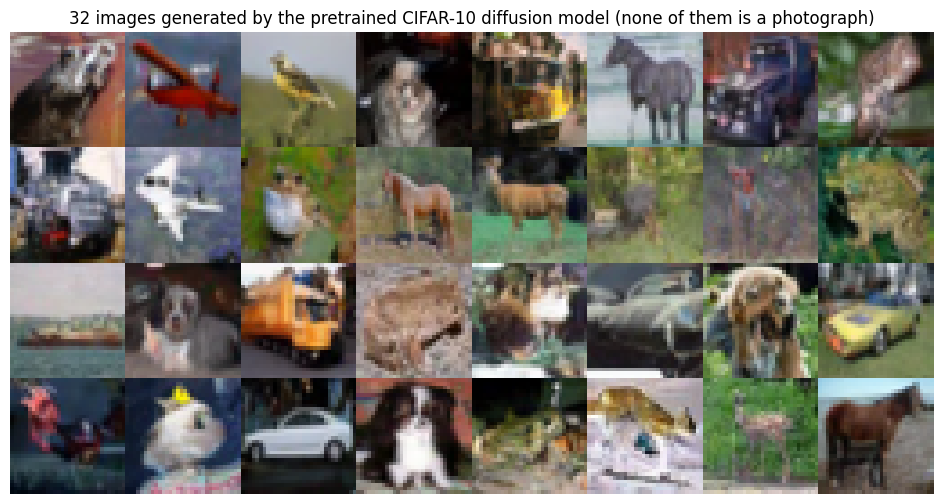

In [25]:
import os
import warnings
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'           # no download progress bars in the output
warnings.filterwarnings('ignore')
try:
    from diffusers import DDIMPipeline, DDPMPipeline
    from diffusers.utils import logging
    logging.set_verbosity_error()
    logging.disable_progress_bar()
except ImportError:
    DDPMPipeline = None
    print('The diffusers package is not installed. To run this section: pip install diffusers, then restart the kernel.')

if DDPMPipeline is not None:
    if device.type == 'cuda':
        pipeline, steps = DDPMPipeline.from_pretrained('google/ddpm-cifar10-32'), 1000
    else:
        pipeline, steps = DDIMPipeline.from_pretrained('google/ddpm-cifar10-32'), 50
    pipeline = pipeline.to(device)
    pipeline.set_progress_bar_config(disable=True)
    parameters = sum(p.numel() for p in pipeline.unet.parameters())
    start = time.time()
    cifar_generated = pipeline(batch_size=32, num_inference_steps=steps, generator=torch.manual_seed(0), output_type='np').images
    seconds = time.time() - start
    print(f'{parameters / 1e6:.1f} million parameters; 32 images, {steps} steps: {seconds:.0f} s')
    print(f'RESULT cifar_ddpm: {parameters} {steps} {seconds:.1f}')

    sheet = np.concatenate([np.concatenate(list(cifar_generated[r * 8:(r + 1) * 8]), axis=1) for r in range(4)], axis=0)
    plt.figure(figsize=(12, 6)); plt.imshow(sheet, interpolation='nearest'); plt.axis('off')
    plt.title('32 images generated by the pretrained CIFAR-10 diffusion model (none of them is a photograph)'); plt.show()

No label was given, so the model draws "any CIFAR-10 photo". Look closely: some outputs are convincing cars, horses or ships, and some only have the colors and textures of a photo without being any object. At 32 x 32 pixels, with 50,000 training photos, this is what the method reaches.

## Things to Try

1. In Section 2, train an autoencoder with `k = 64`. Does the error keep falling? Compare with PCA at 64 components.
2. In Section 3, raise `NOISE` to 1.0 and train the denoiser again. Where does it start inventing the wrong digit?
3. In Section 6, set `RETRAIN = True` and train the GAN with a different seed. Do the same digits come out too often?
4. In Section 7, call `generate(10, labels=torch.full((10,), 7), seed=...)` with a few seeds, and look at the variety of sevens.
5. In Section 7, generate with `steps=10` and `steps=50`. Where does the gray share reach the level of real digits?

In [26]:
# The stored networks of Sections 2 to 5, and the arrays that the lecture's figures and demo pages are drawn from
if small is None:
    small = {f'autoencoder{k}': autoencoders[k].state_dict() for k in autoencoders}
    small.update(denoiser=denoiser.state_dict(), classifier=classifier.state_dict(), completer=completer.state_dict())
    torch.save(small, 'output/gv_small_networks.pth')

def u8(images):
    return (np.asarray(images.detach().cpu() if torch.is_tensor(images) else images) * 255).round().astype(np.uint8)

trajectories = {}
for steps in (1000, 100, 20, 5):
    final, rec = generate(20, labels=torch.arange(10).repeat(2), steps=steps, seed=11, record=True)
    pick = sorted(set(np.linspace(0, len(rec) - 1, min(len(rec), 41)).round().astype(int).tolist()))
    trajectories[f'traj{steps}_t'] = np.array([rec[j][0] for j in pick])
    trajectories[f'traj{steps}_x'] = np.stack([(rec[j][1].numpy() / 3 * 127).round().clip(-127, 127) for j in pick]).astype(np.int8)
    trajectories[f'traj{steps}_x0'] = np.stack([u8((rec[j][2] + 1) / 2) for j in pick])
    ab = alpha_bar.cpu()
    noise = [(rec[j][1] - ab[rec[j][0]].sqrt() * rec[j][2]) / (1 - ab[rec[j][0]]).sqrt() for j in pick]      # the noise that goes with each estimate
    trajectories[f'traj{steps}_noise'] = np.stack([(e.numpy() / 4 * 127).round().clip(-127, 127) for e in noise]).astype(np.int8)
    trajectories[f'traj{steps}_final'] = u8(final)
decoder = autoencoders[2].decoder
np.savez_compressed(
    'output/generative_vision.npz',
    random_images=u8(random_images), recon_rows=u8(recon_rows),
    codes2=codes2[:3000].astype(np.float32), codes2_labels=labels_test[:3000], codes2_low=low, codes2_high=high, decoded_grid=u8(decoded_grid),
    **{f'decoder_w{n}': decoder[i].weight.detach().cpu().numpy() for n, i in enumerate((0, 2, 4))},
    **{f'decoder_b{n}': decoder[i].bias.detach().cpu().numpy() for n, i in enumerate((0, 2, 4))},
    test_digits=u8(X_test[:200]), test_labels=labels_test[:200], test_codes2=codes2[:200].astype(np.float32),
    denoise_rows=u8(torch.cat([X_test[:10], noisy[:10].clamp(0, 1), cleaned[:10]])),
    interpolation=u8(torch.stack(strips)), from_random_codes=u8(from_random_codes[:40]),
    completion=u8(torch.cat([X_test[:20], completed[:20]])), explain=u8(torch.stack([torch.cat([X_test[i, :14][None], r]) for i, r in zip(uncertain, explain_rows)])),
    gan_samples=u8(torch.stack(history['samples'])), gan_counts=np.stack([c.cpu().numpy() for c in history['counts']]),
    gan_loss_D=np.array(history['loss_D']), gan_loss_G=np.array(history['loss_G']),
    gan_score_real=np.array(history['score_real']), gan_score_fake=np.array(history['score_fake']),
    gan_images=u8(gan_images[:40]), gan_walks=u8(torch.stack(gan_walks)), gan_final_counts=gan_counts, real_counts=real_counts,
    forward_example=u8(((forward_example[:, 0] + 1) / 2).clamp(0, 1)), forward_levels=np.array(levels),
    alpha_bar=alpha_bar.cpu().numpy(), diffusion_loss=np.array(diffusion['loss']),
    conditional=u8(conditional), unconditional=u8(unconditional[:30]),
    step_images=u8(torch.stack([step_images[s][:10] for s in (1000, 100, 20, 5)])),
    cifar_generated=u8(cifar_generated) if DDPMPipeline is not None else np.zeros(0),
    **trajectories)
print('saved output/generative_vision.npz')

saved output/generative_vision.npz
